# Phase 1 – Part B: Supervised Learning – Model Comparison & Analysis
## Executive Clinical Screening & Triage Decision-Support Tool
**SWE485 – King Saud University – Group 3**

This notebook compares the three supervised models developed in Phase 1:

| Model | Detailed notebook (justification, tuning, cross-validation) |
|---|---|
| Logistic Regression | `Supervised_Learning/Phase1_Logistic_Regression.ipynb` |
| Random Forest | `Supervised_Learning/Phase1_Random_Forest.ipynb` |
| XGBoost | `Supervised_Learning/Phase1_XGBoost.ipynb` |

**Fair comparison protocol.** Each model is the *final tuned version* from its notebook. All three are evaluated here on the **same shared test set** (`Dataset/test_data.csv`, 13,812 rows), with the **same metrics** and the **same decision threshold (0.5)**. The comparison is *between different models*, not between baseline and tuned versions of the same model (that is covered inside each model's notebook).

**Evaluation priority.** The system is a *screening* tool: missing an at-risk person (False Negative) is more costly than an extra referral (False Positive). Therefore:
- **Recall** (positive class) is the primary metric – it measures how many at-risk individuals are caught.
- **F1-score** balances Recall with Precision, so that we do not refer everybody.
- **ROC-AUC** measures how well the model separates the two classes across all thresholds.
- **Accuracy** is reported, but is not used alone to choose the model.

## 1. Setup

In [2]:
import time, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

### 1.1 Paths

In [3]:
# Works whether the notebook is run from the repo root or from Supervised_Learning/
BASE = Path(".") if Path("Dataset").exists() else Path("..")
DATA_DIR    = BASE / "Dataset"
SL_DIR      = BASE / "Supervised_Learning"
MODELS_DIR  = SL_DIR / "models"
PLOTS_DIR   = SL_DIR / "plots"
RESULTS_DIR = SL_DIR / "evaluation_results"
for d in (MODELS_DIR, PLOTS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

TARGET = "Diabetes_binary"

### 1.2 Load the shared train/test split
The same split is used by all three model notebooks. Tree-based models (Random Forest, XGBoost) use the original
feature values; Logistic Regression uses the standardized version of **the same rows** (`*_scaled.csv`), exactly as
in its own notebook.

In [4]:
def load_xy(path):
    df = pd.read_csv(path)
    return df.drop(columns=[TARGET]), df[TARGET].astype(int)

X_train,   y_train   = load_xy(DATA_DIR / "train_data.csv")
X_test,    y_test    = load_xy(DATA_DIR / "test_data.csv")
X_train_s, y_train_s = load_xy(DATA_DIR / "train_data_scaled.csv")
X_test_s,  y_test_s  = load_xy(DATA_DIR / "test_data_scaled.csv")

assert (y_test.values == y_test_s.values).all() and (y_train.values == y_train_s.values).all(), \
    "Scaled and unscaled files must contain the same rows in the same order."

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTest class balance:\n", y_test.value_counts().rename({0: "0 - No diabetes", 1: "1 - Prediabetes/Diabetes"}))

Train: (55245, 21) | Test: (13812, 21)

Test class balance:
 Diabetes_binary
1 - Prediabetes/Diabetes    7020
0 - No diabetes             6792
Name: count, dtype: int64


### 1.3 The three tuned models
| Model | Source | Tuned hyperparameters (from the model's notebook) | Data |
|---|---|---|---|
| Logistic Regression | Re-fitted here with the tuned hyperparameters | `C=0.1`, `solver='lbfgs'`, `max_iter=1000` (GridSearchCV, 5-fold, F1) | scaled |
| Random Forest | Loaded from `models/random_forest_model.joblib` | `n_estimators=100`, `max_depth=10`, `min_samples_split=2`, `min_samples_leaf=1` (RandomizedSearchCV, 5-fold, F1) | original |
| XGBoost | Re-fitted here with the tuned hyperparameters | `learning_rate=0.05`, `max_depth=5`, `n_estimators=200` (GridSearchCV, 5-fold, F1) | original |

The XGBoost notebook did not export its final model file, so XGBoost is re-fitted here with **exactly the tuned hyperparameters** found in its notebook, on the same training data. Logistic Regression is re-fitted in the same way for consistency (its saved model, `logistic_regression_model.pkl`, uses the same hyperparameters). The re-fitted models are saved to `Supervised_Learning/models/` so all three tuned models are available for Phase 2. Section 1.4 verifies that the models reproduce the results reported in each model's notebook.

In [5]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

DATA = {  # which version of the shared split each model uses
    "Logistic Regression": {"train": X_train_s, "test": X_test_s},
    "Random Forest":       {"train": X_train,   "test": X_test},
    "XGBoost":             {"train": X_train,   "test": X_test},
}

models = {}
models["Logistic Regression"] = LogisticRegression(C=0.1, solver="lbfgs", max_iter=1000, random_state=42) \
                                    .fit(X_train_s, y_train)
models["Random Forest"] = joblib.load(MODELS_DIR / "random_forest_model.joblib")
models["XGBoost"] = XGBClassifier(learning_rate=0.05, max_depth=5, n_estimators=200).fit(X_train, y_train)

joblib.dump(models["Logistic Regression"], MODELS_DIR / "logistic_regression_model.joblib")
joblib.dump(models["XGBoost"], MODELS_DIR / "xgboost_model.joblib")

for name, m in models.items():
    print(f"{name:20s} {type(m).__name__}")

Logistic Regression  LogisticRegression
Random Forest        RandomForestClassifier
XGBoost              XGBClassifier


### 1.4 Check: results match each model's notebook

In [6]:
REPORTED = {  # tuned-model test results as printed in each model's notebook
    "Logistic Regression": {"Recall": 0.7738, "F1-score": 0.7557, "ROC-AUC": 0.8184},
    "Random Forest":       {"Recall": 0.7973, "F1-score": 0.7610, "ROC-AUC": 0.8198},
    "XGBoost":             {"Recall": 0.8041, "F1-score": 0.7660, "ROC-AUC": 0.8241},
}
rows = []
for name, m in models.items():
    p = m.predict_proba(DATA[name]["test"])[:, 1]; pr = (p >= 0.5).astype(int)
    now = {"Recall": recall_score(y_test, pr), "F1-score": f1_score(y_test, pr), "ROC-AUC": roc_auc_score(y_test, p)}
    for k, v in now.items():
        rows.append({"Model": name, "Metric": k, "Notebook": REPORTED[name][k], "Here": round(v, 4),
                     "Match": "yes" if abs(v - REPORTED[name][k]) < 0.003 else "CHECK"})
check = pd.DataFrame(rows)
display(check)
print("All results reproduced." if (check["Match"] == "yes").all()
      else "Some values differ - check that the model notebooks and this notebook use the same data files.")

,Model,Metric,Notebook,Here,Match
0,Logistic Regression,Recall,0.7738,0.7738,yes
1,Logistic Regression,F1-score,0.7557,0.7557,yes
2,Logistic Regression,ROC-AUC,0.8184,0.8184,yes
3,Random Forest,Recall,0.7973,0.7973,yes
4,Random Forest,F1-score,0.7610,0.7610,yes
5,Random Forest,ROC-AUC,0.8198,0.8198,yes
6,XGBoost,Recall,0.8041,0.8041,yes
7,XGBoost,F1-score,0.7660,0.7660,yes
8,XGBoost,ROC-AUC,0.8241,0.8241,yes


All results reproduced.


## 2. Performance comparison on the shared test set
All models predict the **same** test rows; class 1 (*Prediabetes/Diabetes*) is treated as the positive class.

In [7]:
preds, probas, results = {}, {}, []
for name, model in models.items():
    Xm = DATA[name]["test"]
    t0 = time.perf_counter()
    proba = model.predict_proba(Xm)[:, 1]
    pred_time = time.perf_counter() - t0
    pred = (proba >= 0.5).astype(int)
    preds[name], probas[name] = pred, proba
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1-score":  f1_score(y_test, pred),
        "ROC-AUC":   roc_auc_score(y_test, proba),
        "_pred_time_s": pred_time,
    })

results_df = pd.DataFrame(results).set_index("Model")
METRICS = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

if results_df["ROC-AUC"].min() < 0.6:
    print("[!] Warning: a model has ROC-AUC < 0.6. Check that the test set has the same preprocessing "
          "(e.g. scaling) that the model was trained with.")

display(results_df[METRICS].style.format("{:.4f}")
        .highlight_max(axis=0, color="#c6efce")
        .set_caption("Model comparison on the shared test set (best value per metric highlighted)"))

best_per_metric = pd.DataFrame({"Best model": results_df[METRICS].idxmax(),
                                "Value": results_df[METRICS].max().round(4)})
display(best_per_metric)
results_df[METRICS].round(4).to_csv(RESULTS_DIR / "model_comparison.csv")

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7457,0.7383,0.7738,0.7557,0.8184
Random Forest,0.7454,0.7278,0.7973,0.7610,0.8198
XGBoost,0.7504,0.7314,0.8041,0.7660,0.8241


,Best model,Value
Accuracy,XGBoost,0.7504
Precision,Logistic Regression,0.7383
Recall,XGBoost,0.8041
F1-score,XGBoost,0.7660
ROC-AUC,XGBoost,0.8241


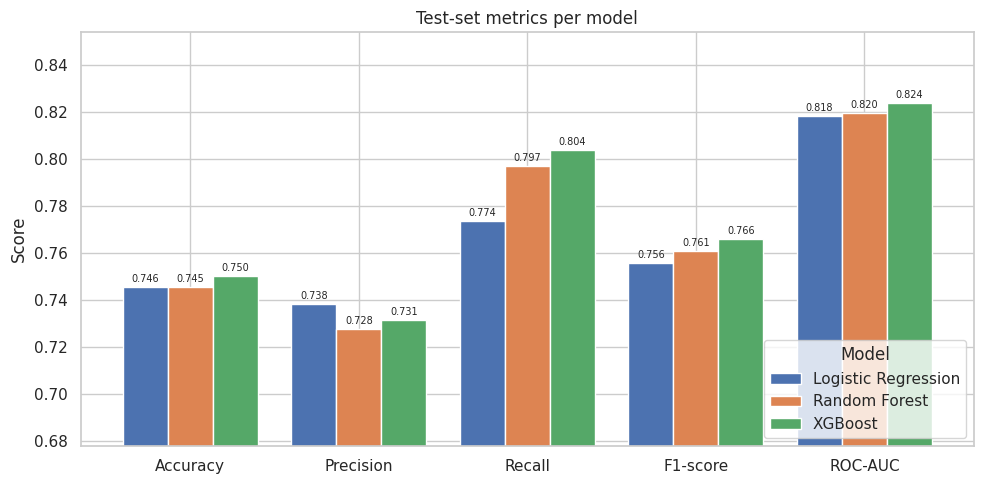

In [8]:
ax = results_df[METRICS].T.plot(kind="bar", figsize=(10, 5), rot=0, width=0.8)
lo = max(0, results_df[METRICS].values.min() - 0.05)
ax.set_ylim(lo, min(1, results_df[METRICS].values.max() + 0.03))
ax.set_title("Test-set metrics per model"); ax.set_ylabel("Score"); ax.legend(title="Model", loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "comparison_metrics_bar.png", dpi=150); plt.show()

### 2.1 ROC curves

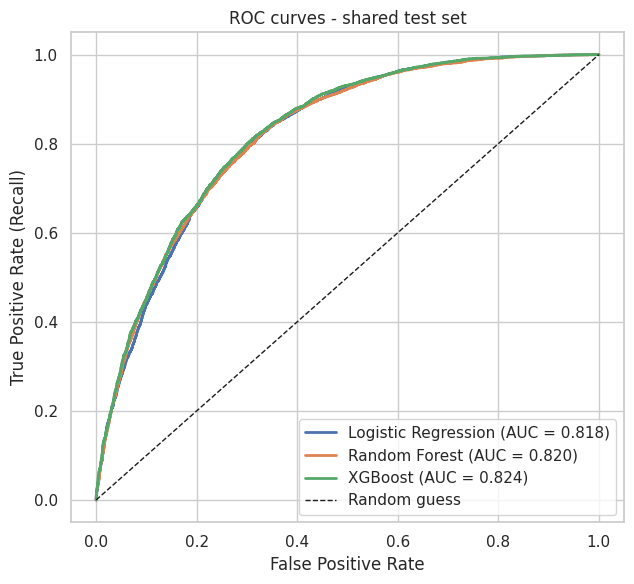

In [9]:
plt.figure(figsize=(6.5, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves - shared test set"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "comparison_roc_curves.png", dpi=150); plt.show()

### 2.2 Metric interpretation

In [10]:
r = results_df
best = lambda m: r[m].idxmax()
spread = lambda m: r[m].max() - r[m].min()
display(Markdown(f'''
- **Recall:** highest for **{best("Recall")}** ({r["Recall"].max():.3f}). Range across models: {spread("Recall"):.3f}.
- **F1-score:** highest for **{best("F1-score")}** ({r["F1-score"].max():.3f}). Range: {spread("F1-score"):.3f}.
- **ROC-AUC:** highest for **{best("ROC-AUC")}** ({r["ROC-AUC"].max():.3f}). Range: {spread("ROC-AUC"):.3f}.
- **Precision:** highest for **{best("Precision")}** ({r["Precision"].max():.3f}).
- **Accuracy:** highest for **{best("Accuracy")}** ({r["Accuracy"].max():.3f}). Range: {spread("Accuracy"):.3f}.

Because the dataset is balanced (50/50), accuracy is not misleading here, but it weights a missed patient
and an unnecessary referral equally, which does not match the screening goal - so Recall and F1 drive the decision.
'''))


- **Recall:** highest for **XGBoost** (0.804). Range across models: 0.030.
- **F1-score:** highest for **XGBoost** (0.766). Range: 0.010.
- **ROC-AUC:** highest for **XGBoost** (0.824). Range: 0.006.
- **Precision:** highest for **Logistic Regression** (0.738).
- **Accuracy:** highest for **XGBoost** (0.750). Range: 0.005.

Because the dataset is balanced (50/50), accuracy is not misleading here, but it weights a missed patient
and an unnecessary referral equally, which does not match the screening goal - so Recall and F1 drive the decision.


## 3. Confusion matrix comparison
- **TP** – at-risk person correctly referred.  **TN** – healthy person correctly given routine follow-up.
- **FP** – healthy person referred unnecessarily (extra clinical workload).
- **FN** – at-risk person *missed* (the most costly error for screening).

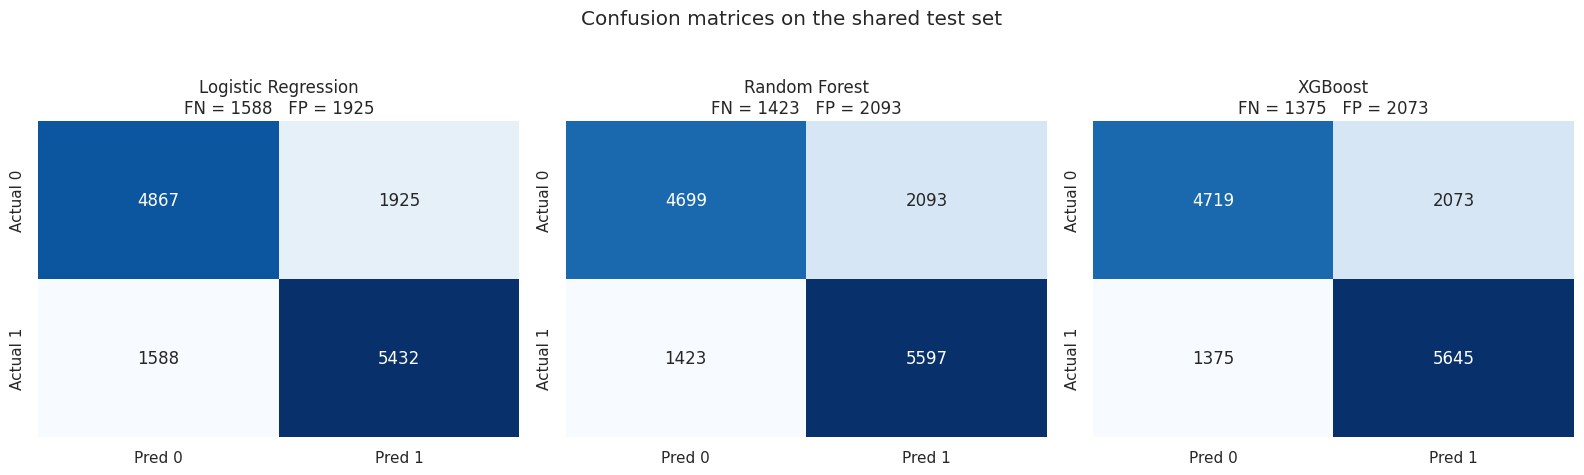

,TP,TN,FP,FN,Miss rate (FN/(FN+TP)),False alarm rate (FP/(FP+TN))
Model,,,,,,
Logistic Regression,5432,4867,1925,1588,0.226,0.283
Random Forest,5597,4699,2093,1423,0.203,0.308
XGBoost,5645,4719,2073,1375,0.196,0.305


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
cm_rows = []
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({"Model": name, "TP": tp, "TN": tn, "FP": fp, "FN": fn,
                    "Miss rate (FN/(FN+TP))": fn / (fn + tp),
                    "False alarm rate (FP/(FP+TN))": fp / (fp + tn)})
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"])
    ax.set_title(f"{name}\nFN = {fn}   FP = {fp}")
plt.suptitle("Confusion matrices on the shared test set", y=1.03)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "comparison_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

cm_df = pd.DataFrame(cm_rows).set_index("Model")
display(cm_df.style.format({"Miss rate (FN/(FN+TP))": "{:.3f}", "False alarm rate (FP/(FP+TN))": "{:.3f}"})
        .highlight_min(subset=["FN", "FP"], color="#c6efce")
        .highlight_max(subset=["TP", "TN"], color="#c6efce"))
cm_df.to_csv(RESULTS_DIR / "confusion_matrix_comparison.csv")

## 4. Misclassification comparison
We look at *which* positive cases each model misses (False Negatives), whether the models miss the same people, and whether certain groups are harder for one model than another.

### 4.1 Overlap of missed at-risk cases

In [12]:
pos = (y_test.values == 1)
missed = pd.DataFrame({n: (p == 0) & pos for n, p in preds.items()}, index=X_test.index)
n_missed_by = missed.sum(axis=1)

overlap = pd.Series({
    "Missed by all three models": int((n_missed_by == 3).sum()),
    "Missed by exactly two":      int((n_missed_by == 2).sum()),
    "Missed by exactly one":      int((n_missed_by == 1).sum()),
    "Caught by all three":        int(((n_missed_by == 0) & pos).sum()),
}, name="Positive test cases")
display(overlap.to_frame())

only_one = {n: int((missed[n] & (n_missed_by == 1)).sum()) for n in models}
display(pd.Series(only_one, name="FN that ONLY this model makes").to_frame())

,Positive test cases
Missed by all three models,1132
Missed by exactly two,296
Missed by exactly one,398
Caught by all three,5194


,FN that ONLY this model makes
Logistic Regression,252
Random Forest,96
XGBoost,50


### 4.2 Profile of missed cases (False Negatives) vs. caught cases (True Positives)
If FNs have *lower* average risk-factor values than TPs, the model is missing people whose indicators look "healthy" – i.e. hard, atypical cases.

In [13]:
KEY_FEATURES = [f for f in ["HighBP", "HighChol", "BMI", "GenHlth", "Age", "DiffWalk",
                            "PhysActivity", "HeartDiseaseorAttack", "PhysHlth", "Income"]
                if f in X_test.columns]
rows = {}
for n in models:
    fn_mask = missed[n]
    tp_mask = pos & (preds[n] == 1)
    rows[(n, "FN mean")] = X_test.loc[fn_mask, KEY_FEATURES].mean()
    rows[(n, "TP mean")] = X_test.loc[tp_mask, KEY_FEATURES].mean()
profile = pd.DataFrame(rows).T.round(2)
display(profile)
print("Values are in original units: binary indicators = share of people with the condition; "
      "BMI in kg/m2; Age = age category (1 = 18-24 ... 13 = 80+); GenHlth 1 = excellent ... 5 = poor; "
      "PhysHlth = days of poor physical health in the last 30; Income = category (1 = lowest ... 8 = highest).")

HighBP  HighChol    BMI  GenHlth   Age  DiffWalk  \
Logistic Regression FN mean    0.37      0.38  27.95     2.45  8.38      0.11   
                    TP mean    0.87      0.75  32.87     3.53  9.68      0.45   
Random Forest       FN mean    0.34      0.39  28.11     2.39  8.52      0.08   
                    TP mean    0.86      0.74  32.68     3.51  9.61      0.45   
XGBoost             FN mean    0.37      0.39  27.71     2.42  8.39      0.11   
                    TP mean    0.85      0.73  32.74     3.50  9.63      0.44   

                             PhysActivity  HeartDiseaseorAttack  PhysHlth  \
Logistic Regression FN mean          0.76                  0.06      3.91   
                    TP mean          0.60                  0.28      9.23   
Random Forest       FN mean          0.78                  0.04      2.91   
                    TP mean          0.60                  0.27      9.33   
XGBoost             FN mean          0.77                  0.05      3.51   
                    TP mean          0.60                  0.27      9.13   

                             Income  
Logistic Regression FN mean    6.16  
                    TP mean    4.94  
Random Forest       FN mean    6.16  
                    TP mean    4.98  
XGBoost             FN mean    6.16  
                    TP mean    4.99

Values are in original units: binary indicators = share of people with the condition; BMI in kg/m2; Age = age category (1 = 18-24 ... 13 = 80+); GenHlth 1 = excellent ... 5 = poor; PhysHlth = days of poor physical health in the last 30; Income = category (1 = lowest ... 8 = highest).


### 4.3 Miss rate by subgroup (where does each model struggle more?)

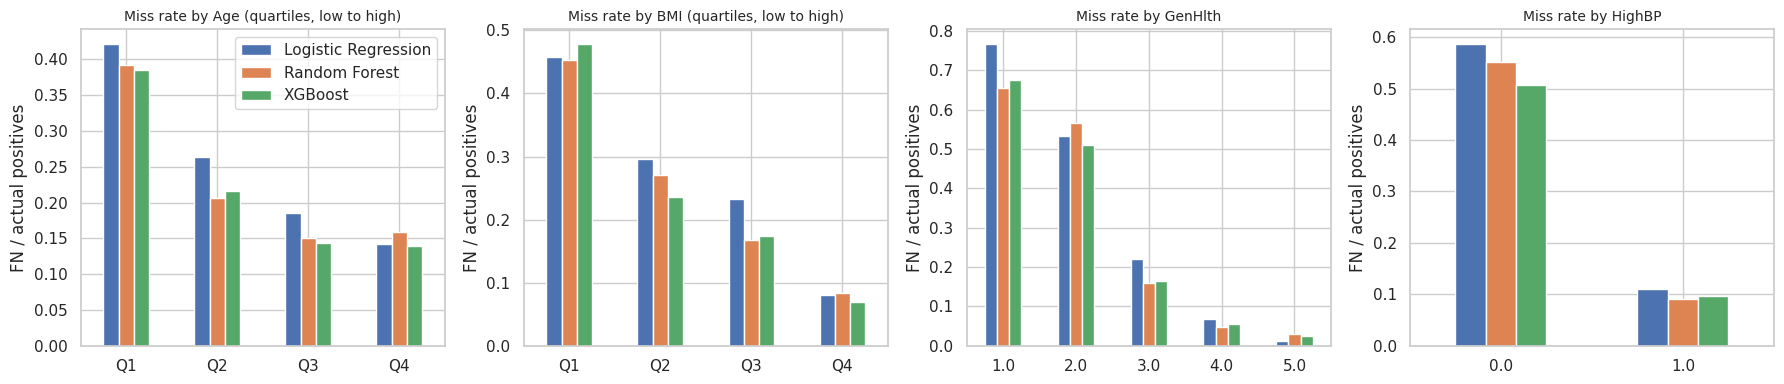

In [14]:
def miss_rate_by(feature, bins=4):
    col = X_test[feature]
    groups = (pd.qcut(col.rank(method="first"), q=bins, labels=[f"Q{i+1}" for i in range(bins)])
              if col.nunique() > 6 else col.round(2).astype(str))
    out = {}
    for n in models:
        df = pd.DataFrame({"g": groups[pos], "missed": missed[n][pos]})
        out[n] = df.groupby("g", observed=True)["missed"].mean()
    return pd.DataFrame(out)

sub_feats = [f for f in ["Age", "BMI", "GenHlth", "HighBP"] if f in X_test.columns]
fig, axes = plt.subplots(1, len(sub_feats), figsize=(4.5 * len(sub_feats), 4), squeeze=False)
subgroup_tables = {}
for ax, f in zip(axes[0], sub_feats):
    t = miss_rate_by(f)
    subgroup_tables[f] = t
    t.plot(kind="bar", ax=ax, rot=0, legend=(f == sub_feats[0]))
    ax.set_title(f"Miss rate by {f}" + (" (quartiles, low to high)" if X_test[f].nunique() > 6 else ""),
                 fontsize=10)
    ax.set_ylabel("FN / actual positives"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "comparison_miss_rate_by_subgroup.png", dpi=150); plt.show()

In [15]:
fewest_fn = cm_df["FN"].idxmin(); most_fn = cm_df["FN"].idxmax()
fewest_fp = cm_df["FP"].idxmin()
lines = [f"- **{fewest_fn}** has the fewest False Negatives ({cm_df.loc[fewest_fn, 'FN']}), "
         f"vs. {cm_df.loc[most_fn, 'FN']} for **{most_fn}** "
         f"({cm_df.loc[most_fn, 'FN'] - cm_df.loc[fewest_fn, 'FN']} more at-risk people missed).",
         f"- **{fewest_fp}** has the fewest False Positives ({cm_df.loc[fewest_fp, 'FP']}), i.e. the fewest unnecessary referrals.",
         f"- {overlap['Missed by all three models']} positive cases are missed by **all three** models "
         f"({overlap['Missed by all three models'] / max(1, missed.any(axis=1).sum()):.0%} of all cases missed by any model). "
         "These are inherently hard cases rather than a weakness of one specific algorithm."]
for n in models:
    lower = [f for f in KEY_FEATURES if f not in ("PhysActivity", "Income")
             and profile.loc[(n, "FN mean"), f] < profile.loc[(n, "TP mean"), f]]
    if lower:
        lines.append(f"- {n}: missed cases have lower average {', '.join(lower[:4])} than caught cases "
                     "- the model misses at-risk people whose risk factors look mild.")
for f, t in subgroup_tables.items():
    hardest = t.mean(axis=1).idxmax()
    worst_model = t.loc[hardest].idxmax()
    lines.append(f"- By **{f}**: the hardest group is **{hardest}** (avg miss rate {t.loc[hardest].mean():.2f}); "
                 f"**{worst_model}** struggles most there ({t.loc[hardest].max():.2f}).")
display(Markdown("**Misclassification findings**\n\n" + "\n".join(lines)))

**Misclassification findings**

- **XGBoost** has the fewest False Negatives (1375), vs. 1588 for **Logistic Regression** (213 more at-risk people missed).
- **Logistic Regression** has the fewest False Positives (1925), i.e. the fewest unnecessary referrals.
- 1132 positive cases are missed by **all three** models (62% of all cases missed by any model). These are inherently hard cases rather than a weakness of one specific algorithm.
- Logistic Regression: missed cases have lower average HighBP, HighChol, BMI, GenHlth than caught cases - the model misses at-risk people whose risk factors look mild.
- Random Forest: missed cases have lower average HighBP, HighChol, BMI, GenHlth than caught cases - the model misses at-risk people whose risk factors look mild.
- XGBoost: missed cases have lower average HighBP, HighChol, BMI, GenHlth than caught cases - the model misses at-risk people whose risk factors look mild.
- By **Age**: the hardest group is **Q1** (avg miss rate 0.40); **Logistic Regression** struggles most there (0.42).
- By **BMI**: the hardest group is **Q1** (avg miss rate 0.46); **XGBoost** struggles most there (0.48).
- By **GenHlth**: the hardest group is **1.0** (avg miss rate 0.70); **Logistic Regression** struggles most there (0.77).
- By **HighBP**: the hardest group is **0.0** (avg miss rate 0.55); **Logistic Regression** struggles most there (0.59).

## 5. Trade-offs: Accuracy vs. Interpretability vs. Computational Cost
### 5.1 Computational cost
Training time is measured by re-fitting each tuned model (same hyperparameters) on the shared training set; prediction time is measured on the full test set.

In [16]:
cost = []
for name, model in models.items():
    row = {"Model": name, "Prediction time (ms, full test set)": results_df.loc[name, "_pred_time_s"] * 1000}
    if X_train is not None:
        m = clone(model)
        t0 = time.perf_counter(); m.fit(DATA[name]["train"], y_train)
        row["Training time (s)"] = time.perf_counter() - t0
    est = model.steps[-1][1] if hasattr(model, "steps") else model
    if hasattr(est, "coef_"):
        row["Model size"] = f"{est.coef_.size + 1} parameters (coefficients + intercept)"
    elif hasattr(est, "estimators_"):
        row["Model size"] = f"{len(est.estimators_)} trees, max depth {getattr(est, 'max_depth', None)}"
    elif hasattr(est, "get_booster"):
        row["Model size"] = f"{len(est.get_booster().get_dump())} boosted trees, max depth {est.get_params().get('max_depth')}"
    cost.append(row)
cost_df = pd.DataFrame(cost).set_index("Model")
display(cost_df.style.format({c: "{:.2f}" for c in cost_df.columns if "time" in c}))

,"Prediction time (ms, full test set)",Training time (s),Model size
Model,,,
Logistic Regression,3.21,0.50,22 parameters (coefficients + intercept)
Random Forest,143.54,3.29,"100 trees, max depth 10"
XGBoost,48.16,2.60,"200 boosted trees, max depth 5"


### 5.2 Interpretability: what drives each model's prediction?

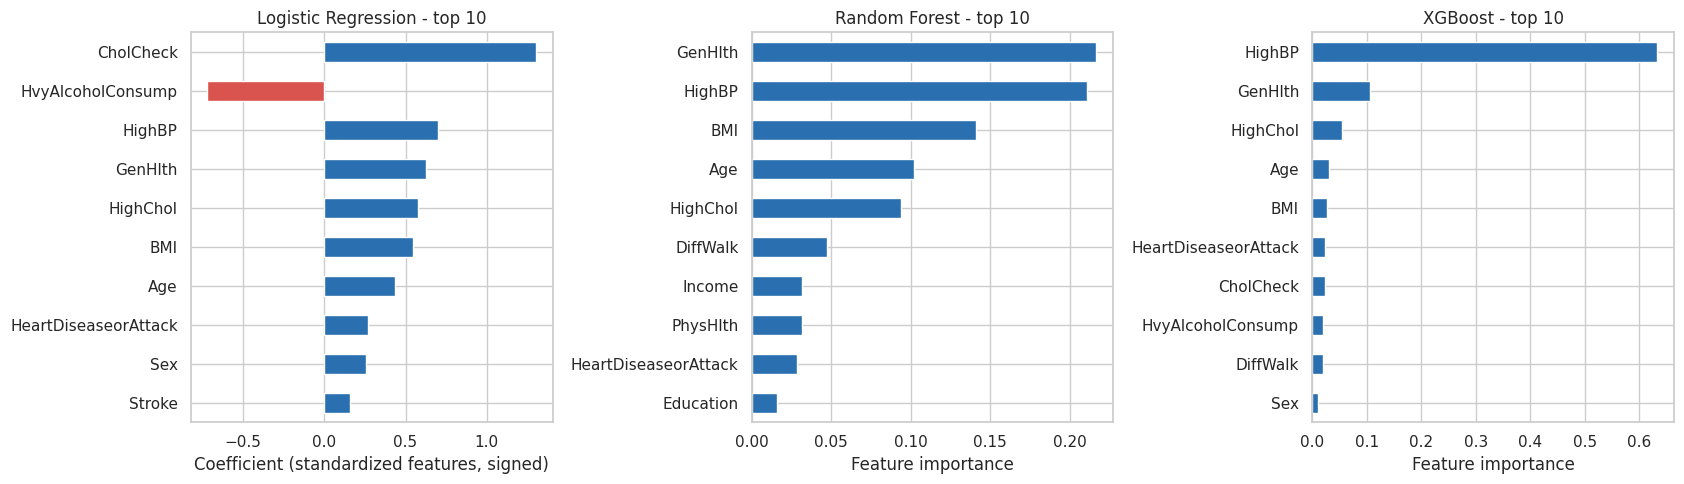

,Logistic Regression,Random Forest,XGBoost
Top-5 features,,,
#1,CholCheck,GenHlth,HighBP
#2,HvyAlcoholConsump,HighBP,GenHlth
#3,HighBP,BMI,HighChol
#4,GenHlth,Age,Age
#5,HighChol,HighChol,BMI


In [17]:
def importances(model):
    est = model.steps[-1][1] if hasattr(model, "steps") else model
    names = list(X_test.columns)
    if hasattr(est, "coef_"):
        return pd.Series(est.coef_.ravel(), index=names), "Coefficient (standardized features, signed)"
    return pd.Series(est.feature_importances_, index=names), "Feature importance"

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
top_feats = {}
for ax, (name, model) in zip(axes, models.items()):
    s, label = importances(model)
    top = s.reindex(s.abs().sort_values(ascending=False).index)[:10][::-1]
    top_feats[name] = list(top.index[::-1][:5])
    top.plot(kind="barh", ax=ax, color=["#d9534f" if v < 0 else "#2a6fb0" for v in top])
    ax.set_title(f"{name} - top 10"); ax.set_xlabel(label)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "comparison_feature_importance.png", dpi=150); plt.show()
display(pd.DataFrame(top_feats, index=[f"#{i+1}" for i in range(5)]).rename_axis("Top-5 features"))

### 5.3 Trade-off summary

| Aspect | Logistic Regression | Random Forest | XGBoost |
|---|---|---|---|
| **Predictive performance** | See Section 2 – strong when relationships are close to linear/additive | Captures non-linear relationships and feature interactions | Usually the strongest on tabular data; captures non-linear interactions with boosting |
| **Interpretability** | **Highest** – each coefficient has a direct direction and size (log-odds), easy to explain to clinicians and executives | Medium – global feature importance, but individual predictions come from hundreds of trees | Lowest of the three – needs extra tools (e.g. SHAP) to explain an individual prediction |
| **Computational cost** | **Lowest** – trains in seconds, tiny model, instant prediction | Highest memory (many deep trees); slower training and prediction | Moderate–high training cost and many hyperparameters to tune; fast prediction |
| **Robustness / tuning effort** | Few hyperparameters, stable | Few important hyperparameters, robust to outliers | Most hyperparameters, most sensitive to tuning |

The measured values in Sections 2 and 5.1 confirm (or adjust) these general expectations for our dataset.

## 6. Conclusion: Best Model Selection & Reasoning
**Selection rule (decided before looking at the winner, to stay objective and aligned with the project goal):**
1. Keep only models whose **F1-score is within 0.02** of the best F1 – the model must stay balanced and must not achieve high recall simply by referring everybody.
2. Among those, choose the model with the **highest Recall** (fewest missed at-risk individuals).
3. If Recall is tied (within 0.005), prefer the higher **ROC-AUC**, then the lower computational cost / higher interpretability.

In [18]:
r = results_df.copy()
cands = r[r["F1-score"] >= r["F1-score"].max() - 0.02]
top_recall = cands["Recall"].max()
tied = cands[cands["Recall"] >= top_recall - 0.005]
SELECTED = tied["ROC-AUC"].idxmax() if len(tied) > 1 else tied.index[0]
s, c = r.loc[SELECTED], cm_df.loc[SELECTED]
others = [m for m in r.index if m != SELECTED]

def fn_phrase(m):
    d = int(cm_df.loc[m, "FN"] - c["FN"])
    return (f"misses **{d} fewer** at-risk people than {m}" if d > 0 else
            f"misses **{-d} more** at-risk people than {m}" if d < 0 else f"misses the same number of at-risk people as {m}")

TRADEOFF_NOTE = {
    "Logistic Regression": "It is also the most interpretable and cheapest model: each coefficient can be explained directly "
                           "to clinicians and executives, and it trains and predicts almost instantly.",
    "Random Forest": "It captures non-linear relationships and interactions between risk factors, and its feature importance "
                     "gives a clear global explanation; its higher memory/computational cost is acceptable for a screening tool.",
    "XGBoost": "Its lower interpretability compared with Logistic Regression is the main trade-off; it will be mitigated in "
               "Phase 2 by showing the top contributing features (and optionally SHAP values) next to each prediction.",
}
table = "\n".join(f"| {m} | {s[m]:.4f} | {r.loc[others[0], m]:.4f} | {r.loc[others[1], m]:.4f} |" for m in METRICS)
table += f"\n| False Negatives | {int(c['FN'])} | {int(cm_df.loc[others[0], 'FN'])} | {int(cm_df.loc[others[1], 'FN'])} |"
higher_auc = [m for m in others if r.loc[m, "ROC-AUC"] > s["ROC-AUC"]]
auc_note = (f"ROC-AUC of {s['ROC-AUC']:.3f} shows good separation of the two classes"
            + (f" ({', '.join(higher_auc)} is slightly higher on AUC, but at the 0.5 operating point "
               f"{SELECTED} catches more at-risk people)" if higher_auc else " and is the best of the three") + ".")

display(Markdown(f'''
### Selected model: **{SELECTED}**

| Metric | **{SELECTED}** | {others[0]} | {others[1]} |
|---|---|---|---|
{table}

**Why {SELECTED}:**
- It detects **{s["Recall"]:.1%}** of at-risk individuals (Recall) on the shared test set, while keeping a balanced
  F1-score of {s["F1-score"]:.3f} - so referrals remain meaningful and clinical capacity is not wasted.
- On {int(pos.sum())} positive test cases, it {fn_phrase(others[0])} and {fn_phrase(others[1])}.
- {auc_note} This matters because the Phase 2 dashboard will display a continuous **risk probability**, not only a yes/no label.
- {TRADEOFF_NOTE.get(SELECTED, "")}
- The decision is based on the screening objective (minimising missed cases with a balanced F1), **not on accuracy alone**.
'''))


### Selected model: **XGBoost**

| Metric | **XGBoost** | Logistic Regression | Random Forest |
|---|---|---|---|
| Accuracy | 0.7504 | 0.7457 | 0.7454 |
| Precision | 0.7314 | 0.7383 | 0.7278 |
| Recall | 0.8041 | 0.7738 | 0.7973 |
| F1-score | 0.7660 | 0.7557 | 0.7610 |
| ROC-AUC | 0.8241 | 0.8184 | 0.8198 |
| False Negatives | 1375 | 1588 | 1423 |

**Why XGBoost:**
- It detects **80.4%** of at-risk individuals (Recall) on the shared test set, while keeping a balanced
  F1-score of 0.766 - so referrals remain meaningful and clinical capacity is not wasted.
- On 7020 positive test cases, it misses **213 fewer** at-risk people than Logistic Regression and misses **48 fewer** at-risk people than Random Forest.
- ROC-AUC of 0.824 shows good separation of the two classes and is the best of the three. This matters because the Phase 2 dashboard will display a continuous **risk probability**, not only a yes/no label.
- Its lower interpretability compared with Logistic Regression is the main trade-off; it will be mitigated in Phase 2 by showing the top contributing features (and optionally SHAP values) next to each prediction.
- The decision is based on the screening objective (minimising missed cases with a balanced F1), **not on accuracy alone**.


### 6.1 Operating threshold for screening
The comparison above uses the default 0.5 threshold for fairness. For deployment, the threshold of the selected model can be lowered to catch more at-risk individuals, at the cost of more referrals:

In [19]:
p = probas[SELECTED]
thr = []
for t in [0.30, 0.35, 0.40, 0.45, 0.50]:
    pr = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pr).ravel()
    thr.append({"Threshold": t, "Recall": recall_score(y_test, pr), "Precision": precision_score(y_test, pr),
                "F1-score": f1_score(y_test, pr), "FN (missed)": fn, "FP (extra referrals)": fp,
                "Referred (%)": pr.mean() * 100})
thr_df = pd.DataFrame(thr).set_index("Threshold")
display(thr_df.style.format({"Recall": "{:.3f}", "Precision": "{:.3f}", "F1-score": "{:.3f}", "Referred (%)": "{:.1f}"}))
thr_df.round(4).to_csv(RESULTS_DIR / f"threshold_analysis_selected_model.csv")

,Recall,Precision,F1-score,FN (missed),FP (extra referrals),Referred (%)
Threshold,,,,,,
0.300000,0.927,0.664,0.773,512,3300,71.0
0.350000,0.906,0.681,0.777,663,2980,67.6
0.400000,0.876,0.697,0.776,872,2669,63.8
0.450000,0.844,0.714,0.773,1097,2373,60.1
0.500000,0.804,0.731,0.766,1375,2073,55.9


In [20]:
f1_range = results_df["F1-score"].max() - results_df["F1-score"].min()
share_all = overlap["Missed by all three models"] / max(1, missed.any(axis=1).sum())
closeness = ("The three models perform within a close range (F1 spread {:.3f}), which indicates that the predictive "
             "signal in the BRFSS indicators is captured similarly by all three algorithms.".format(f1_range)
             if f1_range < 0.02 else
             "There is a clear performance gap between the models (F1 spread {:.3f}), so algorithm choice matters "
             "for this dataset.".format(f1_range))
display(Markdown(f'''
**Final remarks.** {closeness} {share_all:.0%} of the at-risk cases missed by any model are missed by **all three**,
so a large part of the remaining error comes from cases whose recorded indicators do not reveal the risk, rather than
from the algorithm itself. The selection therefore rests on the screening objective (Recall with a balanced F1), with
interpretability and computational cost as secondary criteria. The system remains a **decision-support tool**:
final decisions stay with qualified clinicians.
'''))


**Final remarks.** The three models perform within a close range (F1 spread 0.010), which indicates that the predictive signal in the BRFSS indicators is captured similarly by all three algorithms. 62% of the at-risk cases missed by any model are missed by **all three**,
so a large part of the remaining error comes from cases whose recorded indicators do not reveal the risk, rather than
from the algorithm itself. The selection therefore rests on the screening objective (Recall with a balanced F1), with
interpretability and computational cost as secondary criteria. The system remains a **decision-support tool**:
final decisions stay with qualified clinicians.


## 7. Next Steps for Phase 2 Integration
1. **Unsupervised learning (Part A).** Apply clustering (e.g. K-Means and Gaussian Mixture / Hierarchical) to the same preprocessed features **without the target column** to discover patient risk segments (e.g. *older adults with high blood pressure and cholesterol*, *younger adults with high BMI and low physical activity*). Each segment will be profiled and compared with the selected model's predicted risk, so the dashboard can show both *how likely* a person is to be at risk and *which group* they resemble.
2. **Generative AI (Part B).** The selected model's risk probability, the assigned cluster, and the person's top contributing features (Section 5.2) will be passed into prompt templates of an LLM to generate a short, personalised **preventive-care summary**. At least two prompt templates will be compared for clarity, accuracy and hallucination, and the output will always state that it is not a diagnosis.
3. **Dashboard (Part C).** The saved selected model (`Supervised_Learning/models/`) will be loaded by a Streamlit dashboard with sliders for BMI, age, blood pressure and other indicators, a live **diabetes-risk gauge** driven by `predict_proba`, a **cluster badge**, and the **AI-generated summary**. The referral threshold will be configurable based on the analysis in Section 6.1 so that decision-makers can balance missed cases against clinical capacity.
4. **Pipeline consistency.** The same preprocessing steps from `Phase1_Data_Exploration.ipynb` will be applied to dashboard inputs before prediction, so that live predictions match the evaluated model.